### Dataset Selection

I selected the Titanic Dataset from the Seaborn Open Dataset Repository. It contains passenger information such as age, gender, ticket class, fare and survival status. It includes numerical and categorical data with missing values, making it suitable for data cleaning and EDA.

**Dataset Details:**

* Dataset Name: Titanic Dataset
* Domain: Transport
* File Format: CSV
* Rows: 891
* Columns: 15
* Target Column: survived
* Source: https://github.com/mwaskom/seaborn-data


**Step 2: Load and Inspect the Dataset**

The Titanic dataset was loaded into Python using the Pandas library. The first and last five rows were displayed to understand the dataset. The shape, column names and data types were also checked.

The dataset contains 891 rows and 15 columns, including numerical and categorical data. The info() and describe() functions were used to examine the dataset structure and summary statistics.



In [7]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Upload the Titanic dataset
from google.colab import files
uploaded = files.upload()

# Load the CSV file
df = pd.read_csv("titanic.csv")

# Display first 5 rows
print("First 5 Rows:")
display(df.head())

# Display last 5 rows
print("Last 5 Rows:")
display(df.tail())

# Display number of rows and columns
print("Dataset Shape:", df.shape)
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

# Display column names
print("\nColumn Names:")
print(df.columns.tolist())

# Display dataset information and data types
print("\nDataset Information:")
df.info()

# Display basic statistical information
print("\nStatistical Summary:")
display(df.describe())

Saving titanic.csv to titanic (2).csv
First 5 Rows:


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


Last 5 Rows:


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
886,0,2,male,27.0,0,0,13.00,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.00,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.45,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.00,C,First,man,True,C,Cherbourg,yes,True
890,0,3,male,32.0,0,0,7.75,Q,Third,man,True,NaN,Queenstown,no,True


Dataset Shape: (891, 15)
Number of Rows: 891
Number of Columns: 15

Column Names:
['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    object 
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    object 
 8   class        891 non-null    object 
 9   who          891 non-null    object 
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    object 
 12  embark_town  889 non-null    object 
 13  alive     

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


### Step 3: Identify Data Types and Basic Statistics

The dataset contains both numerical and categorical columns. Numerical columns were analyzed using summary statistics such as mean, minimum and maximum. Categorical columns were examined using frequency counts.

The `survived` column was identified as the target column for future prediction. Unusual values and unique categories were also inspected.


In [8]:
# Step 3: Identify Data Types and Basic Statistics

# Display all column data types
print("Data Types:")
print(df.dtypes)

# Separate numerical columns
numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns
print("\nNumerical Columns:")
print(numerical_cols.tolist())

# Separate categorical columns
categorical_cols = df.select_dtypes(include=['object', 'category']).columns
print("\nCategorical Columns:")
print(categorical_cols.tolist())

# Display statistical summary of numerical columns
print("\nNumerical Statistics:")
display(df[numerical_cols].describe())

# Display frequency counts of categorical columns
print("\nCategorical Column Statistics:")
for col in categorical_cols:
    print("\n", col)
    print(df[col].value_counts())

# Identify target column
target_column = 'survived'
print("\nTarget Column:", target_column)

# Check suspicious or unusual values
print("\nUnique Values in Categorical Columns:")
for col in categorical_cols:
    print(col, ":", df[col].unique())

Data Types:
survived         int64
pclass           int64
sex             object
age            float64
sibsp            int64
parch            int64
fare           float64
embarked        object
class           object
who             object
adult_male        bool
deck            object
embark_town     object
alive           object
alone             bool
dtype: object

Numerical Columns:
['survived', 'pclass', 'age', 'sibsp', 'parch', 'fare']

Categorical Columns:
['sex', 'embarked', 'class', 'who', 'deck', 'embark_town', 'alive']

Numerical Statistics:


,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200



Categorical Column Statistics:

 sex
sex
male      577
female    314
Name: count, dtype: int64

 embarked
embarked
S    644
C    168
Q     77
Name: count, dtype: int64

 class
class
Third     491
First     216
Second    184
Name: count, dtype: int64

 who
who
man      537
woman    271
child     83
Name: count, dtype: int64

 deck
deck
C    59
B    47
D    33
E    32
A    15
F    13
G     4
Name: count, dtype: int64

 embark_town
embark_town
Southampton    644
Cherbourg      168
Queenstown      77
Name: count, dtype: int64

 alive
alive
no     549
yes    342
Name: count, dtype: int64

Target Column: survived

Unique Values in Categorical Columns:
sex : ['male' 'female']
embarked : ['S' 'C' 'Q' nan]
class : ['Third' 'First' 'Second']
who : ['man' 'woman' 'child']
deck : [nan 'C' 'E' 'G' 'D' 'A' 'B' 'F']
embark_town : ['Southampton' 'Cherbourg' 'Queenstown' nan]
alive : ['no' 'yes']


### Step 4: Identify Missing Values

Missing values were identified using the `isnull()` function. Their counts and percentages were calculated for each column.

The `age`, `embarked`, `deck` and `embark_town` columns contain missing values. The `deck` column has the highest number of missing values. A heatmap was also created to visualize missing data.


Missing Values in Each Column:
survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

Missing Value Percentage:
survived        0.000000
pclass          0.000000
sex             0.000000
age            19.865320
sibsp           0.000000
parch           0.000000
fare            0.000000
embarked        0.224467
class           0.000000
who             0.000000
adult_male      0.000000
deck           77.216611
embark_town     0.224467
alive           0.000000
alone           0.000000
dtype: float64

Missing Values Summary:


,Missing Values,Percentage (%)
survived,0,0.000000
pclass,0,0.000000
sex,0,0.000000
age,177,19.865320
sibsp,0,0.000000
parch,0,0.000000
fare,0,0.000000
embarked,2,0.224467
class,0,0.000000
who,0,0.000000



Columns Without Missing Values:
['survived', 'pclass', 'sex', 'sibsp', 'parch', 'fare', 'class', 'who', 'adult_male', 'alive', 'alone']

Columns With Missing Values:
['age', 'embarked', 'deck', 'embark_town']


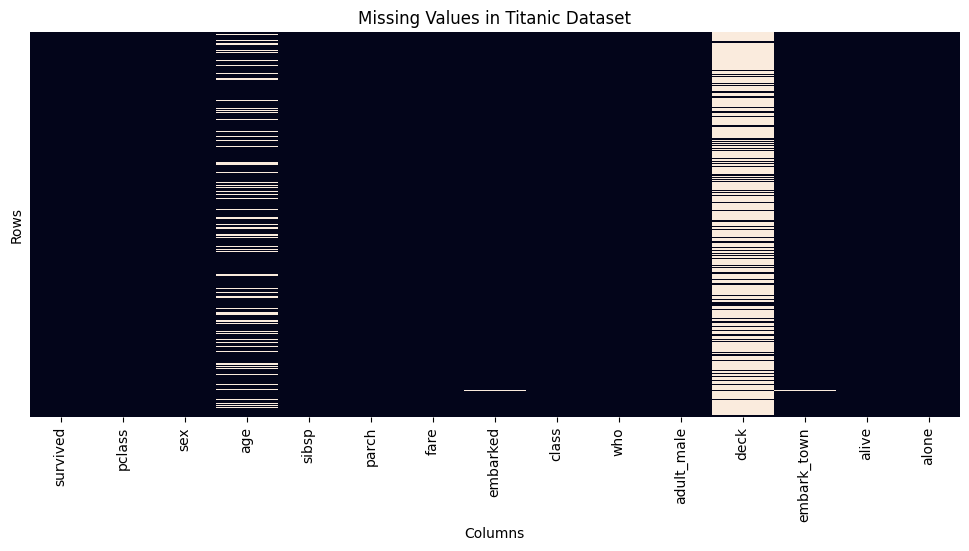

In [9]:
# Count missing values in each column
print("Missing Values in Each Column:")
print(df.isnull().sum())

# Calculate percentage of missing values
missing_percentage = (df.isnull().sum() / len(df)) * 100

print("\nMissing Value Percentage:")
print(missing_percentage)

# Create a summary table
missing_summary = pd.DataFrame({
    'Missing Values': df.isnull().sum(),
    'Percentage (%)': missing_percentage
})

print("\nMissing Values Summary:")
display(missing_summary)

# Identify columns without missing values
print("\nColumns Without Missing Values:")
print(df.columns[df.isnull().sum() == 0].tolist())

# Identify columns containing missing values
print("\nColumns With Missing Values:")
print(df.columns[df.isnull().sum() > 0].tolist())

# Visualize missing values
plt.figure(figsize=(12, 5))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False)
plt.title("Missing Values in Titanic Dataset")
plt.xlabel("Columns")
plt.ylabel("Rows")
plt.show()

### Step 5: Handle Missing Values

Missing values were handled using appropriate methods. The median was used to fill missing values in the Age column, while the mode was used for Embarked and Embark Town columns. The Deck column was removed because it contained approximately 77% missing values.

A copy of the original dataset was maintained. After cleaning, all remaining missing values were checked and the dataset was found to contain zero missing values.


In [10]:

# Making a copy of the original dataset
df_original = df.copy()

# Creating a copy for data cleaning
df_clean = df.copy()

# Checking missing values before cleaning
print("Missing values before cleaning:")
print(df_clean.isnull().sum())

# Filling missing age values with median
df_clean['age'] = df_clean['age'].fillna(df_clean['age'].median())

# Filling missing embarked values with mode
df_clean['embarked'] = df_clean['embarked'].fillna(df_clean['embarked'].mode()[0])

# Filling missing embark_town values with mode
df_clean['embark_town'] = df_clean['embark_town'].fillna(df_clean['embark_town'].mode()[0])

# Removing deck column because it has too many missing values
df_clean = df_clean.drop(columns=['deck'])

# Checking missing values after cleaning
print("\nMissing values after cleaning:")
print(df_clean.isnull().sum())

# Checking total missing values
print("\nTotal missing values:", df_clean.isnull().sum().sum())

# Showing the cleaned dataset
display(df_clean.head())

Missing values before cleaning:
survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

Missing values after cleaning:
survived       0
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       0
class          0
who            0
adult_male     0
embark_town    0
alive          0
alone          0
dtype: int64

Total missing values: 0


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,Southampton,no,True


### Step 6: Check Duplicate Records and Data Consistency

Duplicate records were identified using the `duplicated()` function and removed using `drop_duplicates()`. Categorical columns were also checked for inconsistent values and extra spaces. The dataset was checked again after cleaning to ensure data consistency.


In [11]:
# Step 6: Checking Duplicates and Data Consistency

# Checking duplicate rows
print("Total duplicate rows:")
print(df_clean.duplicated().sum())

# Displaying duplicate records
print("\nDuplicate records:")
display(df_clean[df_clean.duplicated()])

# Removing duplicate rows
df_clean = df_clean.drop_duplicates()

# Checking duplicates after removal
print("\nDuplicates after removal:")
print(df_clean.duplicated().sum())

# Checking unique values in categorical columns
print("\nUnique categorical values:")
for col in df_clean.select_dtypes(include='object').columns:
    print(col, ":", df_clean[col].unique())

# Removing extra spaces from categorical columns
for col in df_clean.select_dtypes(include='object').columns:
    df_clean[col] = df_clean[col].str.strip()

# Checking dataset shape after cleaning
print("\nFinal dataset shape:")
print(df_clean.shape)

# Displaying cleaned data
display(df_clean.head())

Total duplicate rows:
116

Duplicate records:


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,embark_town,alive,alone
47,1,3,female,28.0,0,0,7.7500,Q,Third,woman,False,Queenstown,yes,True
55,1,1,male,28.0,0,0,35.5000,S,First,man,True,Southampton,yes,True
76,0,3,male,28.0,0,0,7.8958,S,Third,man,True,Southampton,no,True
77,0,3,male,28.0,0,0,8.0500,S,Third,man,True,Southampton,no,True
87,0,3,male,28.0,0,0,8.0500,S,Third,man,True,Southampton,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
870,0,3,male,26.0,0,0,7.8958,S,Third,man,True,Southampton,no,True
877,0,3,male,19.0,0,0,7.8958,S,Third,man,True,Southampton,no,True
878,0,3,male,28.0,0,0,7.8958,S,Third,man,True,Southampton,no,True
884,0,3,male,25.0,0,0,7.0500,S,Third,man,True,Southampton,no,True



Duplicates after removal:
0

Unique categorical values:
sex : ['male' 'female']
embarked : ['S' 'C' 'Q']
class : ['Third' 'First' 'Second']
who : ['man' 'woman' 'child']
embark_town : ['Southampton' 'Cherbourg' 'Queenstown']
alive : ['no' 'yes']

Final dataset shape:
(775, 14)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,Southampton,no,True


### Step 7: Exploratory Data Analysis (EDA)

Summary statistics and frequency counts were calculated to understand the dataset. Three graphs were created for better visualization.

**Observations:**

1. Most passengers were young adults.
2. The number of male passengers was higher than female passengers.
3. First-class passengers generally paid higher fares than second- and third-class passengers.


Statistical Summary:


,survived,pclass,age,sibsp,parch,fare
count,775.000000,775.000000,775.000000,775.000000,775.000000,775.000000
mean,0.412903,2.246452,29.581187,0.529032,0.420645,34.878403
std,0.492674,0.853574,13.766359,0.990326,0.840565,52.408474
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,1.000000,21.000000,0.000000,0.000000,8.050000
50%,0.000000,3.000000,28.000000,0.000000,0.000000,15.900000
75%,1.000000,3.000000,36.000000,1.000000,1.000000,34.197900
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200



Passenger Count by Gender:
sex
male      483
female    292
Name: count, dtype: int64

Passenger Count by Class:
class
Third     401
First     210
Second    164
Name: count, dtype: int64


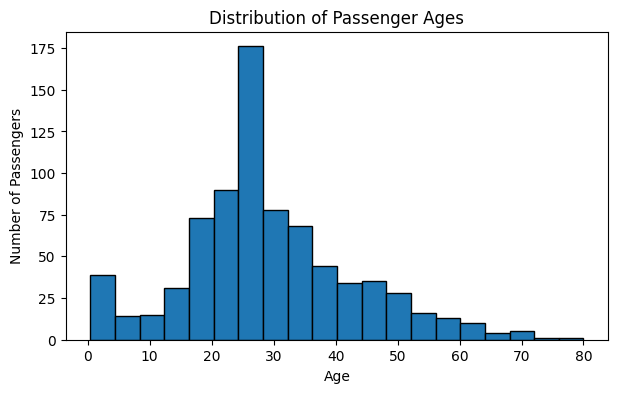

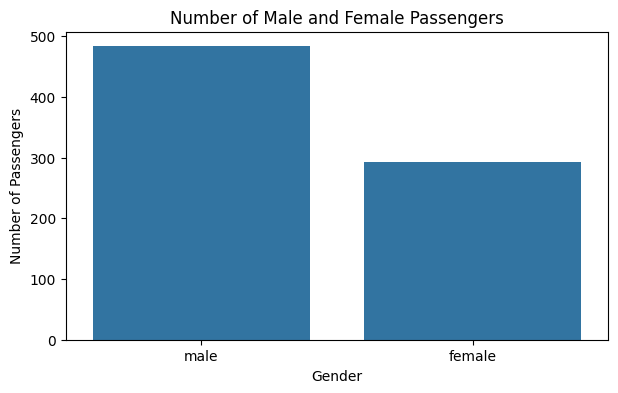

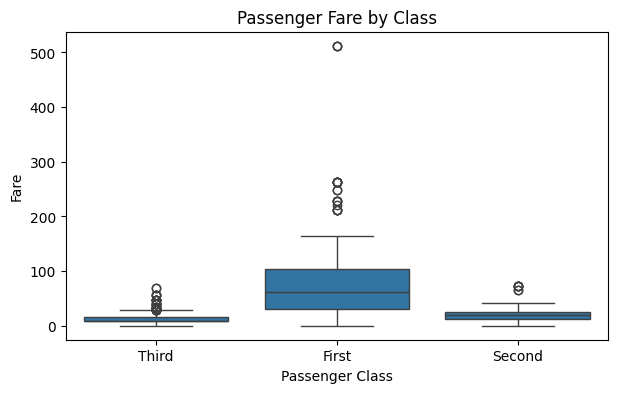


Passenger Survival Count:
survived
0    455
1    320
Name: count, dtype: int64


In [12]:

# Display basic statistics of numerical columns
print("Statistical Summary:")
display(df_clean.describe())

# Display frequency of passengers by gender
print("\nPassenger Count by Gender:")
print(df_clean['sex'].value_counts())

# Display passenger count by ticket class
print("\nPassenger Count by Class:")
print(df_clean['class'].value_counts())

# Create a histogram to show passenger age distribution
plt.figure(figsize=(7, 4))
plt.hist(df_clean['age'], bins=20, edgecolor='black')
plt.title("Distribution of Passenger Ages")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")
plt.show()

# Create a bar chart to show passengers by gender
plt.figure(figsize=(7, 4))
sns.countplot(data=df_clean, x='sex')
plt.title("Number of Male and Female Passengers")
plt.xlabel("Gender")
plt.ylabel("Number of Passengers")
plt.show()

# Create a box plot to compare fares by passenger class
plt.figure(figsize=(7, 4))
sns.boxplot(data=df_clean, x='class', y='fare')
plt.title("Passenger Fare by Class")
plt.xlabel("Passenger Class")
plt.ylabel("Fare")
plt.show()

# Display survival count
print("\nPassenger Survival Count:")
print(df_clean['survived'].value_counts())

### Step 8: Encode Categorical Features

Categorical columns were converted into numerical values using One-Hot Encoding. The `get_dummies()` function was used to create separate columns with 0 and 1 values.

Duplicate information columns were removed before encoding. This makes the dataset suitable for further machine learning operations.


In [13]:
# Step 8: Encoding Categorical Features

# Creating a copy of the cleaned dataset
df_encoded = df_clean.copy()

# Removing columns that contain duplicate information
df_encoded = df_encoded.drop(columns=['alive', 'embark_town', 'class'])

# Checking categorical columns
print("Categorical columns:")
print(df_encoded.select_dtypes(include=['object', 'category', 'bool']).columns.tolist())

# Converting categorical columns into numerical values
df_encoded = pd.get_dummies(
    df_encoded,
    columns=df_encoded.select_dtypes(include=['object', 'category', 'bool']).columns,
    drop_first=True,
    dtype=int
)

# Displaying the dataset after encoding
print("\nDataset after encoding:")
display(df_encoded.head())

# Checking new column names
print("\nColumns after encoding:")
print(df_encoded.columns.tolist())

# Checking final shape
print("\nDataset shape after encoding:")
print(df_encoded.shape)

Categorical columns:
['sex', 'embarked', 'who', 'adult_male', 'alone']

Dataset after encoding:


,survived,pclass,age,sibsp,parch,fare,sex_male,embarked_Q,embarked_S,who_man,who_woman,adult_male_True,alone_True
0,0,3,22.0,1,0,7.2500,1,0,1,1,0,1,0
1,1,1,38.0,1,0,71.2833,0,0,0,0,1,0,0
2,1,3,26.0,0,0,7.9250,0,0,1,0,1,0,1
3,1,1,35.0,1,0,53.1000,0,0,1,0,1,0,0
4,0,3,35.0,0,0,8.0500,1,0,1,1,0,1,1



Columns after encoding:
['survived', 'pclass', 'age', 'sibsp', 'parch', 'fare', 'sex_male', 'embarked_Q', 'embarked_S', 'who_man', 'who_woman', 'adult_male_True', 'alone_True']

Dataset shape after encoding:
(775, 13)


### Step 9: Scale Numerical Features

StandardScaler was used to standardize numerical features such as Age, Fare, SibSp and Parch. It transforms the data to have a mean close to 0 and a standard deviation close to 1.

Scaling helps machine learning algorithms work effectively when features have different measurement ranges.


In [14]:
# Import StandardScaler
from sklearn.preprocessing import StandardScaler

# Creating a copy of the encoded dataset
df_scaled = df_encoded.copy()

# Selecting numerical columns for scaling
scale_cols = ['age', 'fare', 'sibsp', 'parch']

# Applying StandardScaler
scaler = StandardScaler()
df_scaled[scale_cols] = scaler.fit_transform(df_scaled[scale_cols])

# Displaying data after scaling
print("Dataset after scaling:")
display(df_scaled.head())

# Checking the mean and standard deviation after scaling
print("\nMean after scaling:")
print(df_scaled[scale_cols].mean())

print("\nStandard deviation after scaling:")
print(df_scaled[scale_cols].std())

Dataset after scaling:


,survived,pclass,age,sibsp,parch,fare,sex_male,embarked_Q,embarked_S,who_man,who_woman,adult_male_True,alone_True
0,0,3,-0.551060,0.475876,-0.500754,-0.527515,1,0,1,1,0,1,0
1,1,1,0.611945,0.475876,-0.500754,0.695086,0,0,0,0,1,0,0
2,1,3,-0.260308,-0.534545,-0.500754,-0.514627,0,0,1,0,1,0,1
3,1,1,0.393881,0.475876,-0.500754,0.347909,0,0,1,0,1,0,0
4,0,3,0.393881,-0.534545,-0.500754,-0.512240,1,0,1,1,0,1,1



Mean after scaling:
age      2.521281e-16
fare    -1.134576e-16
sibsp   -3.208903e-17
parch    1.375244e-17
dtype: float64

Standard deviation after scaling:
age      1.000646
fare     1.000646
sibsp    1.000646
parch    1.000646
dtype: float64


### Step 10: Save the Prepared Dataset

After completing data cleaning, encoding and scaling, the prepared dataset was saved as `titanic_prepared.csv`.

The final dataset was checked for missing values and duplicate records. The dataset is now prepared for future machine learning applications.


In [15]:
# Step 10: Saving the Prepared Dataset

# Checking the final dataset shape
print("Final Dataset Shape:", df_scaled.shape)

# Checking missing values
print("\nTotal Missing Values:")
print(df_scaled.isnull().sum().sum())

# Checking duplicate rows
print("\nTotal Duplicate Rows:")
print(df_scaled.duplicated().sum())

# Displaying the final prepared dataset
print("\nFinal Prepared Dataset:")
display(df_scaled.head())

# Saving the prepared dataset as a CSV file
df_scaled.to_csv("titanic_prepared.csv", index=False)

print("\nDataset saved successfully!")

# Downloading the prepared CSV file
from google.colab import files
files.download("titanic_prepared.csv")

Final Dataset Shape: (775, 13)

Total Missing Values:
0

Total Duplicate Rows:
0

Final Prepared Dataset:


,survived,pclass,age,sibsp,parch,fare,sex_male,embarked_Q,embarked_S,who_man,who_woman,adult_male_True,alone_True
0,0,3,-0.551060,0.475876,-0.500754,-0.527515,1,0,1,1,0,1,0
1,1,1,0.611945,0.475876,-0.500754,0.695086,0,0,0,0,1,0,0
2,1,3,-0.260308,-0.534545,-0.500754,-0.514627,0,0,1,0,1,0,1
3,1,1,0.393881,0.475876,-0.500754,0.347909,0,0,1,0,1,0,0
4,0,3,0.393881,-0.534545,-0.500754,-0.512240,1,0,1,1,0,1,1



Dataset saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Conclusion

In this activity, I performed data preparation using the Titanic dataset. I inspected the dataset, identified and handled missing values, removed duplicate records, performed EDA and created visualizations. I also applied One-Hot Encoding and StandardScaler.

Finally, the prepared dataset was saved as a CSV file. This activity helped me understand the importance of data cleaning and preprocessing before applying machine learning algorithms.
